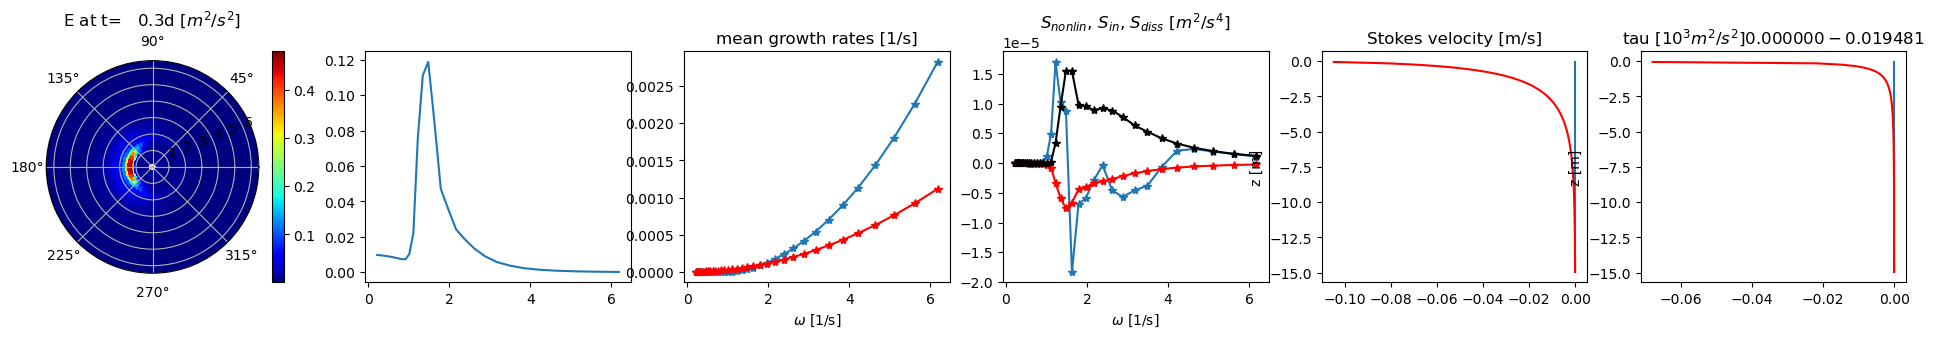

In [1]:
import sys; sys.path.append('/Users/ceden/src/pyOM3')
import pyOM3 as OM
from pyOM3.wim_simple.model import model
import numpy as np
import pylab as plt
from IPython import display


class my_model(model):
    
      def __init__(self,p):
          super().__init__(p)
          self.fig = plt.figure(figsize=(4*6,3))
          return
         
      def diagnose(self,n,tau): 
          
          def spatial_mean(a):
             A = self.nx*self.dx*self.ny*self.dy 
             b = a[...,self.halo:-self.halo,self.halo:-self.halo] 
             return np.sum(np.sum(b*self.dx,axis=-1)*self.dy,axis=-1)/A
              
          def angle_mean(a):
              b = a[self.halo:-self.halo,...]
              return np.sum( b*self.dd,axis=0)/(2*OM.np.pi)
              
          t =  n*self.dt
          #if t>86400: self.udir = self.udir*0 +np.pi/2
          if n==0 or OM.np.mod(t,60*20) == 0: # plotting
             
             Snonlin,_ =  self.Snonlin(self.E)
             Snonlin = angle_mean(  spatial_mean(  Snonlin ) )
             dz, nz = 0.1 ,150
             z = OM.np.arange(nz)*dz 
             z = z - z[-1] - dz/2   
             ust     = self.calc_stokes(dz,nz)[0,:,0,0]
             vst     = self.calc_stokes(dz,nz)[1,:,0,0]
             taux    = self.calc_stress_work(dz,nz)[0,:,0,0]
             tauy    = self.calc_stress_work(dz,nz)[1,:,0,0] 
             staux    = self.calc_stress()[0,0,0]
             stauy    = self.calc_stress()[1,0,0]  
             S_diss = angle_mean( spatial_mean( self.gamma_diss[None,:,:,:]*self.E )) 
             S_in   = angle_mean( spatial_mean( self.gamma_in*self.E ))  
             gamma_diss = spatial_mean( self.gamma_diss ) 
             gamma_in = angle_mean(spatial_mean(self.gamma_in))
             E = spatial_mean(self.E) 
             P = spatial_mean( 2*self.E* self.omega_t[None,:,None,None]**3/self.grav )
              
             self.fig.clf()               
             ax = self.fig.add_subplot(1,6,1, projection='polar') 
             co=plt.pcolormesh(np.linspace(0,2*np.pi,self.nd),self.omega_t[1:-1]
                            ,E[1:-1,1:-1].transpose(),cmap='jet')
             plt.colorbar(co) 
             plt.title('E at t=%6.1fd $[m^2/s^2]$'%(t/86400,))
             #plt.xlabel('$\\omega$ [1/s]')
             ax = self.fig.add_subplot(1,6,2)   
             plt.plot(self.omega_t[1:-1], angle_mean(E)[1:-1] )
              
             ax = self.fig.add_subplot(1,6,3)   
             plt.plot(self.omega_t[1:-1],gamma_in[1:-1],'*-')
             plt.plot(self.omega_t[1:-1],-gamma_diss[1:-1],'r*-')  
             plt.title('mean growth rates [1/s]') 
             plt.xlabel('$\\omega$ [1/s]') 
             ax = self.fig.add_subplot(1,6,4)   
             plt.plot(self.omega_t[1:-1],Snonlin[1:-1],'*-')
             plt.plot(self.omega_t[1:-1],S_diss[1:-1],'r*-')
             plt.plot(self.omega_t[1:-1],S_in[1:-1],'k*-') 
             plt.title('$S_{nonlin}$, $S_{in}$, $S_{diss}$ $[m^2/s^4]$ ')
             plt.xlabel('$\\omega$ [1/s]') 
             ax = self.fig.add_subplot(1,6,5)   
             plt.plot(ust,z,vst,z,'r') 
             plt.title('Stokes velocity [m/s]')
             plt.ylabel('z [m]') 
             ax = self.fig.add_subplot(1,6,6)   
             plt.plot(taux*1e3,z,tauy*1e3,z,'r') 
             
             plt.title('tau $[10^3 m^2/s^2] %f %f$'%(staux*1e3,stauy*1e3))
             plt.ylabel('z [m]') 
 
             display.clear_output(wait=True)  
             display.display(self.fig)
             

p = {'nx':1,'ny':1,'nf':36,'nd':40,'dx':1e3,'dy':1e3,'dt':10*60.,
     'f0':0.035,'df0':0.1,'periodic_in_x':True,'periodic_in_y':True,
     'mask_energy':True,'limit_growth':True,
     'snonlin_backend':'fortran','implicit_dissipation_only':True}


M = my_model(p)
M.setup()
M.E[1:-1,1:-1,1:-1,1:-1] = 1e-2
M.A = M.E/M.omega_t[None,:,None,None]
M.ustar = OM.np.ones( (M.Ny,M.Nx) , OM.prec)*0.35
M.udir  = OM.np.ones( (M.Ny,M.Nx) , OM.prec) *np.pi

try:
    M.loop(int(86400*0.5/M.dt))
except KeyboardInterrupt:
    display.clear_output()